In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print(pd.__version__)

All libraries imported successfully!
3.1.1


In [30]:
df = pd.read_csv("../Data/raw_Customer_Data.csv")

In [31]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [32]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [34]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [35]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [36]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [37]:
df["Churn_encoded"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

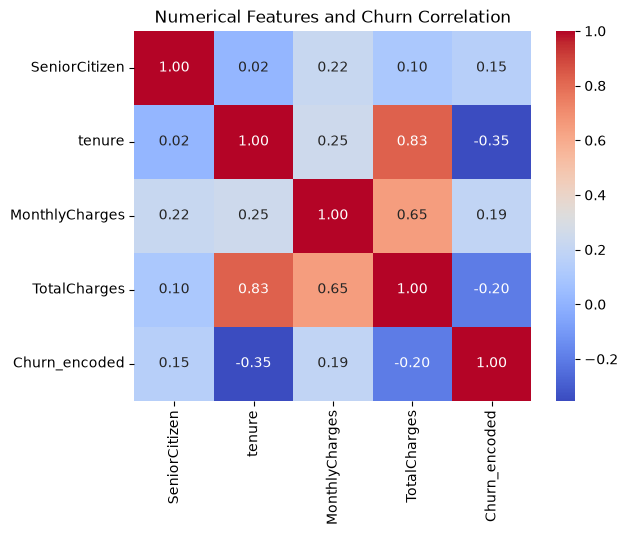

In [38]:
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn_encoded"
]

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Features and Churn Correlation")
plt.show()

In [39]:
df["Churn"].value_counts()


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [40]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

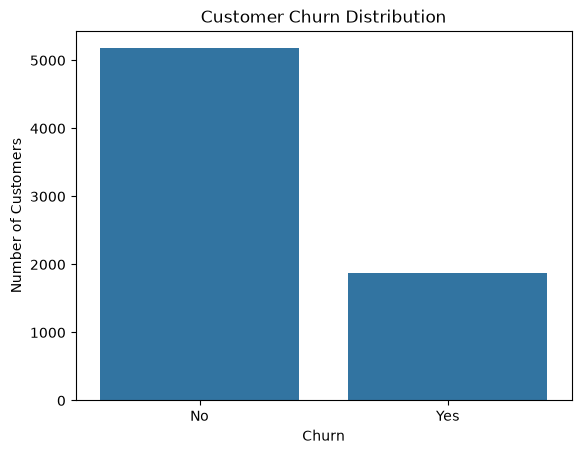

In [41]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

### Target Variable Analysis

The target variable `Churn` contains two classes: `Yes` and `No`.

Approximately 73% of customers did not churn, while 27% churned. This indicates a moderate class imbalance, with the majority class being customers who stayed.

This imbalance should be considered during model evaluation. Accuracy alone may not adequately represent the model's ability to identify customers who churn.

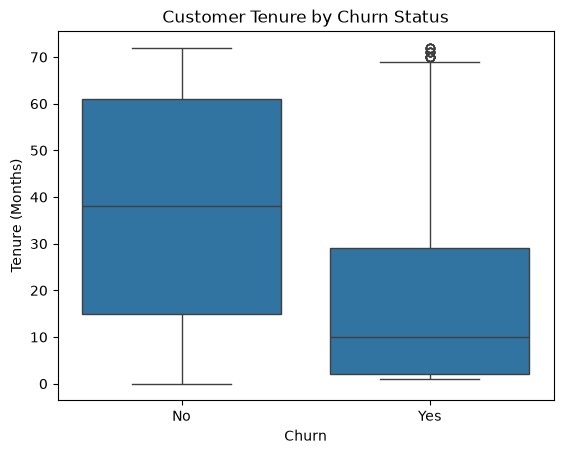

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

### Tenure vs. Churn

The boxplot shows that customers who churned generally have
shorter tenures than customers who stayed.

This suggests that tenure may be an important feature
for predicting customer churn.

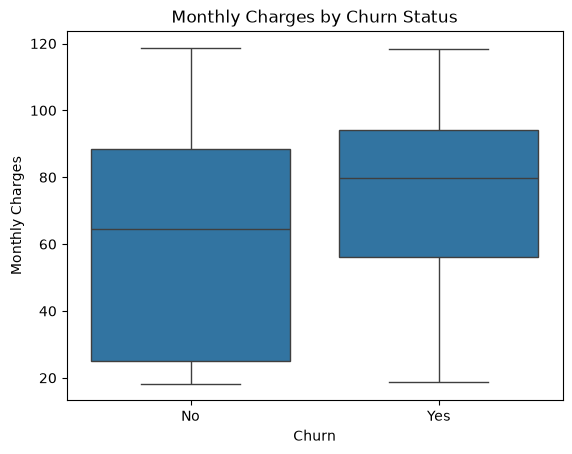

In [43]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

### Monthly Charges vs. Churn

The boxplot shows that customers who churned generally
have higher median monthly charges than customers who stayed.

This suggests that MonthlyCharges may be a useful feature
for predicting customer churn.

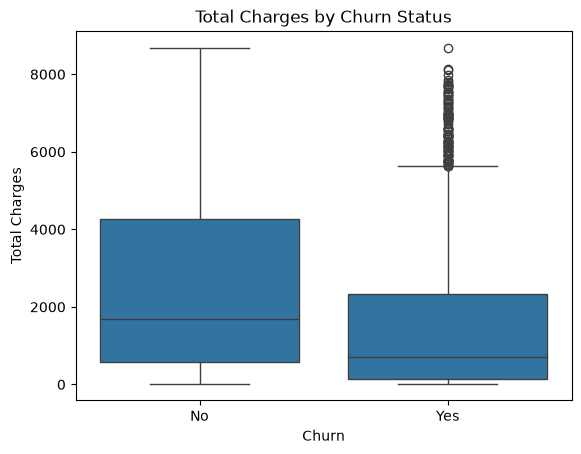

In [44]:
sns.boxplot(data=df, x="Churn", y="TotalCharges")

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

### Total Charges vs. Churn

The boxplot shows that customers who stayed generally
have higher median TotalCharges than customers who churned.

This may be related to tenure, since customers who stay
longer have more time to accumulate total charges.

TotalCharges may be useful for prediction, but its
relationship with tenure should be considered.

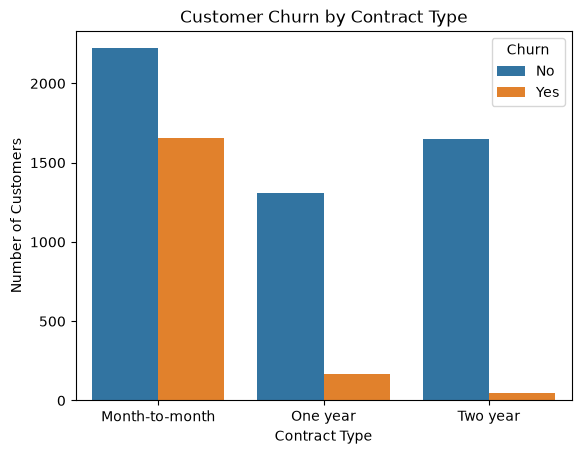

In [45]:
sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [46]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


### Contract vs. Churn

The churn rate is highest among customers with month-to-month
contracts (42.71%).

Customers with one-year contracts have a churn rate of 11.27%,
while customers with two-year contracts have a churn rate of 2.83%.

This suggests that contract type is strongly associated
with customer churn and may be an important predictive feature.

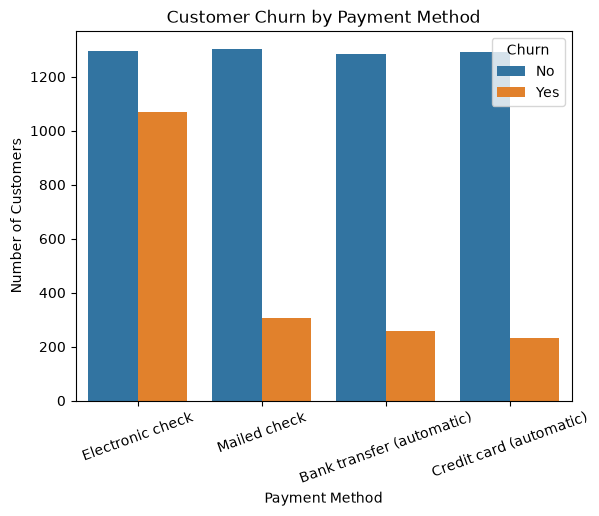

In [47]:
sns.countplot(data=df, x="PaymentMethod", hue="Churn")

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.show()

In [48]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


### Payment Method vs. Churn

Electronic check has the highest churn rate at 45.29%.

Customers using automatic bank transfers and credit cards
have lower churn rates, at 16.71% and 15.24%, respectively.

This suggests that PaymentMethod may be a useful feature
for predicting customer churn.

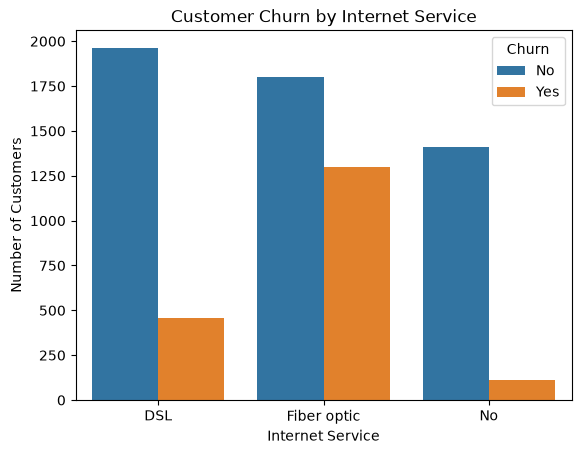

In [49]:
sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [50]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn


Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


### Internet Service vs. Churn

Fiber optic customers have the highest churn rate at 41.89%,
followed by DSL customers at 18.96%.

Customers without internet service have the lowest churn rate
at 7.40%.

This suggests that InternetService may be an important
feature for predicting customer churn.

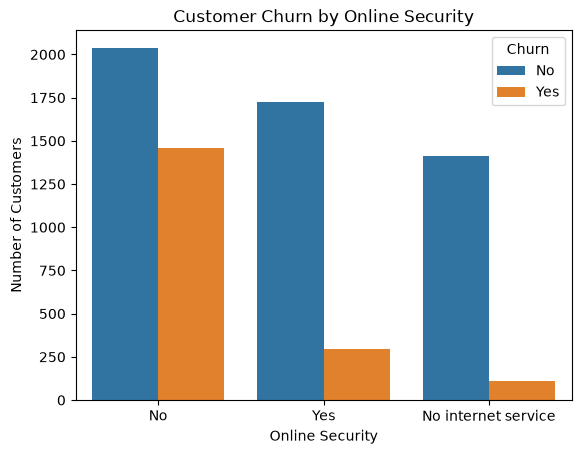

In [51]:
sns.countplot(data=df, x="OnlineSecurity", hue="Churn")

plt.title("Customer Churn by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Number of Customers")

plt.show()

In [52]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

security_churn

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


### Online Security vs. Churn

Customers without online security have a churn rate of 41.77%,
while customers with online security have a churn rate of 14.61%.

Customers without online security appear more likely to churn.

This suggests that OnlineSecurity may be a useful feature
for predicting customer churn.

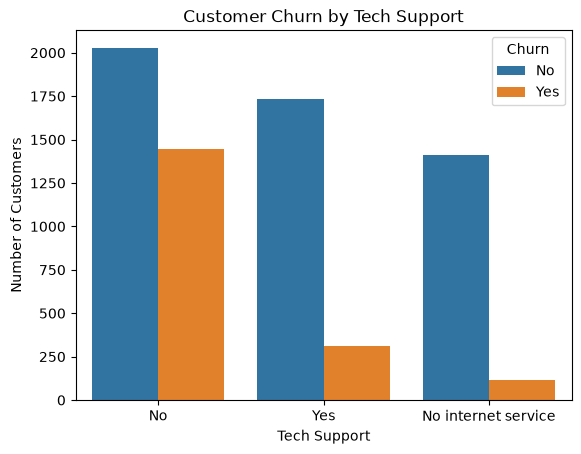

In [53]:
sns.countplot(data=df, x="TechSupport", hue="Churn")

plt.title("Customer Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")

plt.show()

In [54]:
techsupport_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

techsupport_churn

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


### Tech Support vs. Churn

Customers without tech support have a churn rate of 41.64%,
while customers with tech support have a churn rate of 15.17%.

This suggests that TechSupport may be a useful feature
for predicting customer churn.

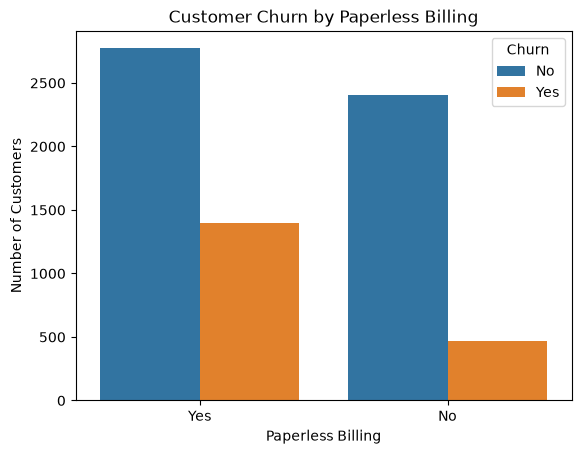

In [55]:
sns.countplot(data=df, x="PaperlessBilling", hue="Churn")

plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")

plt.show()

In [56]:
paperless_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

paperless_churn

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


### Paperless Billing vs. Churn

Customers using paperless billing have a churn rate of 33.57%,
while customers not using paperless billing have a churn rate
of 16.33%.

This suggests that PaperlessBilling may be a useful feature
for predicting customer churn.